# W3 — Global XGBoost against classical methods, weekly sales

**Global:** one XGBoost model for all series (W2). **Classical:** one model per series, fitted to that
series' weekly sales only (`src/weekly_classical.py`): naive, historical mean, moving average (window of 4
weeks, chosen on the validation window), SES, ETS and ARIMA (statsforecast, no seasonality). Same weekly
series, same 4 Sunday origins per window, one week ahead.

Five 4-week windows between 01.02. and 19.06.2016; the hyperparameters of XGBoost were chosen on the fourth
(validation). Tables: `python src/weekly_evaluation.py`; checks: `python src/weekly_checks.py`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT / "src"))

import m5_data as m5
import weekly as W
from plot_style import CONTEXT, INK_SECONDARY, SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results" / "weekly"
wr = pd.read_csv(RESULTS / "wrmsse.csv")
ORDER = ["01.02.-28.02.2016", "29.02.-27.03.2016", "28.03.-24.04.2016", "25.04.-22.05.2016", "23.05.-19.06.2016"]
LEVELS = ["total", "state", "store", "category", "store x category", "item", "item x store"]
MAIN, LAGS, DEFAULT = "XGBoost L+E+S+ID", "XGBoost L", "XGBoost L+E+S+ID, default hyperparameters"
CLASSICAL = ["ARIMA", "ETS", "SES", "Moving average (4 weeks)", "Naive", "Historical mean"]
MODELS = [MAIN, DEFAULT, LAGS] + CLASSICAL
notes = json.loads((RESULTS / "notes.json").read_text())

## 1. Accuracy

In [2]:
acc = wr.pivot(index="model", columns="window", values="WRMSSE").loc[MODELS, ORDER]
acc["mean"] = acc.mean(axis=1)
acc

window,01.02.-28.02.2016,29.02.-27.03.2016,28.03.-24.04.2016,25.04.-22.05.2016,23.05.-19.06.2016,mean
model,,,,,,
XGBoost L+E+S+ID,0.684,0.643,0.561,0.687,0.511,0.617
"XGBoost L+E+S+ID, default hyperparameters",0.762,0.662,0.564,0.701,0.575,0.653
XGBoost L,0.842,0.749,0.650,0.743,0.758,0.748
ARIMA,0.863,0.738,0.688,0.813,0.793,0.779
ETS,0.928,0.739,0.728,0.855,0.849,0.820
SES,0.929,0.740,0.727,0.860,0.850,0.821
Moving average (4 weeks),0.957,0.674,0.714,0.862,0.821,0.806
Naive,0.941,0.937,0.858,0.871,0.999,0.921
Historical mean,1.149,1.021,1.109,1.386,1.443,1.222


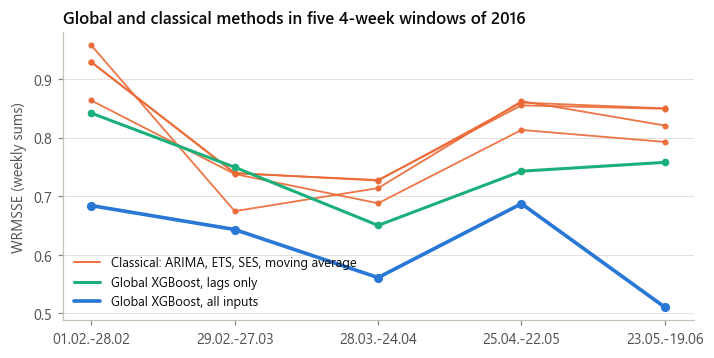

In [3]:
fig, ax = plt.subplots(figsize=(7.4, 3.4))
x = np.arange(len(ORDER))
for m in CLASSICAL[:4]:
    ax.plot(x, acc.loc[m, ORDER], color=SERIES[1], lw=1.2, alpha=0.9, marker="o", ms=3)
ax.plot(x, acc.loc[LAGS, ORDER], color=SERIES[2], lw=2, marker="o", ms=4)
ax.plot(x, acc.loc[MAIN, ORDER], color=SERIES[0], lw=2.4, marker="o", ms=5)
ax.plot([], [], color=SERIES[1], lw=1.2, label="Classical: ARIMA, ETS, SES, moving average")
ax.plot([], [], color=SERIES[2], lw=2, label="Global XGBoost, lags only")
ax.plot([], [], color=SERIES[0], lw=2.4, label="Global XGBoost, all inputs")
ax.set_xticks(x, [w[:12] for w in ORDER])
ax.set_ylabel("WRMSSE (weekly sums)")
ax.set_title("Global and classical methods in five 4-week windows of 2016")
ax.legend(fontsize=8.5)
savefig(fig, "wrmsse_windows", subdir="weekly")
plt.show()

In [4]:
by_level = wr.groupby("model")[LEVELS].mean().loc[MODELS]
by_level.to_csv(RESULTS / "wrmsse_by_level_mean.csv")
by_level

,total,state,store,category,store x category,item,item x store
model,,,,,,,
XGBoost L+E+S+ID,0.399,0.506,0.623,0.521,0.702,0.764,0.803
"XGBoost L+E+S+ID, default hyperparameters",0.394,0.547,0.687,0.559,0.773,0.795,0.812
XGBoost L,0.661,0.692,0.752,0.694,0.811,0.805,0.823
ARIMA,0.725,0.741,0.801,0.744,0.828,0.788,0.825
ETS,0.802,0.799,0.835,0.806,0.858,0.807,0.831
SES,0.805,0.803,0.839,0.809,0.859,0.804,0.827
Moving average (4 weeks),0.745,0.772,0.812,0.780,0.843,0.832,0.855
Naive,0.896,0.898,0.930,0.911,0.972,0.880,0.961
Historical mean,0.905,0.992,1.581,0.952,1.469,1.476,1.176


- The global model with all inputs has the lowest WRMSSE in **every** window; the best classical method,
  ARIMA, is 0.16 behind on average.
- The gap is largest at the top of the hierarchy and small at the item × store level.
- **XGBoost L** sees what the classical methods see, the past sales only. It is better than ARIMA at the
  aggregate levels and equal to it at item × store: learning across series alone gives better sums, not
  better forecasts of single items. Most of the advantage of the full model comes with the other inputs,
  which a model of one series cannot use in the same way (identifiers) or can estimate only from that
  series' short history (prices, events).

## 2. Cost

Minutes of one core per window. Classical methods are timed on one core (400 series, scaled to 30,490);
for XGBoost the wall time on this machine is multiplied by its number of cores, which is an upper bound.
The tuning of XGBoost is a one-off cost (30 trials, 1.69 hours on the 4 cores of a Kaggle CPU kernel).

In [5]:
cost = pd.read_csv(RESULTS / "cost.csv").set_index("model").join(acc["mean"].rename("WRMSSE, mean of 5 windows"))
cost.sort_values("WRMSSE, mean of 5 windows")

,core-minutes per window,core-minutes for a new week,"one-off tuning, core-minutes",training seconds (wall),"memory, GB","WRMSSE, mean of 5 windows"
model,,,,,,
XGBoost L+E+S+ID,8.590,1.078,405.600,59.900,4.390,0.617
"XGBoost L+E+S+ID, default hyperparameters",6.340,1.064,0.000,37.400,4.440,0.653
ARIMA,292.386,0.434,0.000,NaN,NaN,0.779
Moving average (4 weeks),0.001,0.001,0.000,NaN,NaN,0.806
ETS,7.240,0.056,0.000,NaN,NaN,0.820
SES,0.426,0.052,0.000,NaN,NaN,0.821
Naive,0.001,0.001,0.000,NaN,NaN,0.921
Historical mean,0.001,0.001,0.000,NaN,NaN,1.222


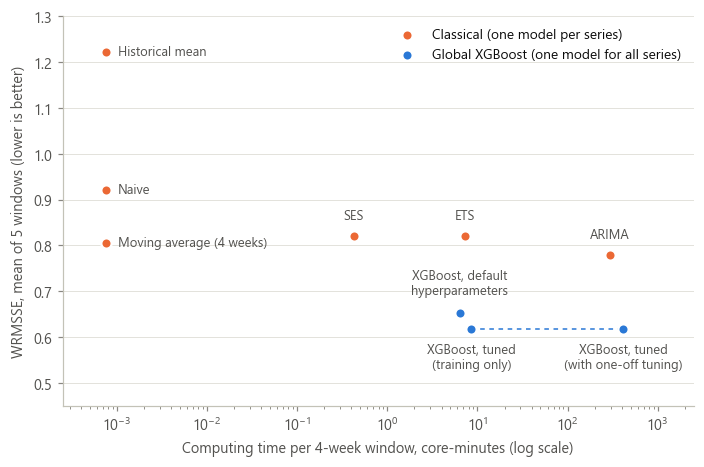

In [6]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
cx, cy = cost["core-minutes per window"], cost["WRMSSE, mean of 5 windows"]
glob = [MAIN, DEFAULT]
tuned_x = cx[MAIN] + cost.loc[MAIN, "one-off tuning, core-minutes"]
ax.plot([cx[MAIN], tuned_x], [cy[MAIN]] * 2, color=SERIES[0], lw=1, ls=(0, (3, 3)), zorder=1)
ax.scatter(cx[CLASSICAL], cy[CLASSICAL], s=46, color=SERIES[1], edgecolor="white", linewidth=1.5, zorder=3, label="Classical (one model per series)")
ax.scatter(list(cx[glob]) + [tuned_x], list(cy[glob]) + [cy[MAIN]], s=46, color=SERIES[0], edgecolor="white", linewidth=1.5, zorder=3,
           label="Global XGBoost (one model for all series)")
labels = {m: (m, (8, 0) if cx[m] < 0.05 else (0, 9)) for m in CLASSICAL}
labels[DEFAULT] = ("XGBoost, default\nhyperparameters", (0, 10))
labels[MAIN] = ("XGBoost, tuned\n(training only)", (0, -9))
for m, (text, (dx, dy)) in labels.items():
    ax.annotate(text, (cx[m], cy[m]), xytext=(dx, dy), textcoords="offset points", ha="left" if dx else "center",
                va="center" if dx else ("bottom" if dy > 0 else "top"), fontsize=8.5, color=INK_SECONDARY)
ax.annotate("XGBoost, tuned\n(with one-off tuning)", (tuned_x, cy[MAIN]), xytext=(0, -9), textcoords="offset points", ha="center", va="top",
            fontsize=8.5, color=INK_SECONDARY)
ax.set_xscale("log")
ax.set_xlim(cx.min() / 3, 2500)
ax.set_ylim(0.45, 1.3)
ax.set_xlabel("Computing time per 4-week window, core-minutes (log scale)")
ax.set_ylabel("WRMSSE, mean of 5 windows (lower is better)")
ax.legend(loc="upper right", frameon=False)
savefig(fig, "accuracy_vs_cost", subdir="weekly")
plt.show()

The global model is both more accurate and cheaper per window than ARIMA, the best classical method,
whose automatic order search takes about half a second per series. Even with its one-off tuning it costs
about as much as one run of ARIMA, and with the default hyperparameters it already beats every classical
method. SES, ETS and the simple methods are cheaper still, but about 0.2 worse.

## 3. Series by series

RMSSE of each item × store series; the main model against each other model.

In [7]:
tests = pd.read_csv(RESULTS / "series_tests.csv")
display(tests.pivot(index="model", columns="window", values="main model better, % of series")[ORDER].round(1))
print("largest Wilcoxon p-value:", tests["Wilcoxon p"].max())
ranks = pd.read_csv(RESULTS / "ranks.csv", index_col=0)
print(f"Friedman test over {notes['series_x_windows']:,} series x windows: p = {notes['friedman_p']:.3g}")
ranks.sort_values("all windows")

window,01.02.-28.02.2016,29.02.-27.03.2016,28.03.-24.04.2016,25.04.-22.05.2016,23.05.-19.06.2016
model,,,,,
ARIMA,53.500,55.400,55.500,55.600,56.000
"Daily main model, summed to weeks",48.900,50.500,50.600,51.600,50.600
ETS,51.700,54.900,54.400,55.700,56.200
Historical mean,61.000,59.800,59.100,58.900,58.500
Moving average (4 weeks),59.000,62.100,62.400,63.200,64.400
Naive,72.600,73.500,76.600,77.400,77.500
SES,51.500,54.700,54.400,55.700,56.100
XGBoost L,58.500,59.000,58.400,57.200,57.600
XGBoost L+E,NaN,NaN,NaN,62.400,61.200


largest Wilcoxon p-value: 0.6983435418599118
Friedman test over 152,436 series x windows: p = 0


,01.02.-28.02.2016,29.02.-27.03.2016,28.03.-24.04.2016,25.04.-22.05.2016,23.05.-19.06.2016,all windows
XGBoost L+E+S+ID,3.921,3.806,3.794,3.763,3.737,3.804
SES,4.106,4.156,4.100,4.134,4.126,4.124
ETS,4.111,4.164,4.106,4.132,4.126,4.128
XGBoost L,4.280,4.216,4.187,4.133,4.135,4.190
ARIMA,4.189,4.225,4.241,4.200,4.197,4.210
Moving average (4 weeks),4.653,4.751,4.725,4.790,4.834,4.751
Historical mean,4.899,4.785,4.730,4.690,4.674,4.755
Naive,5.842,5.898,6.117,6.159,6.169,6.037


The main model is better than SES, ETS and ARIMA on 52-56% of the series in every window and has the
best mean rank; all differences are significant. Per series the advantage is small but consistent.

## 4. Where the global model wins, and where it does not

Mean RMSSE per series, pooled over the five windows.

In [8]:
groups = pd.read_csv(RESULTS / "groups.csv")
cols = ["series x windows", MAIN, LAGS, "SES", "ETS", "ARIMA", "main better than SES, %", "main better than ARIMA, %"]
for g in ["demand class", "sales volume", "category", "history"]:
    display(groups[groups["grouping"] == g].set_index("group")[cols].rename_axis(g))

,series x windows,XGBoost L+E+S+ID,XGBoost L,SES,ETS,ARIMA,"main better than SES, %","main better than ARIMA, %"
demand class,,,,,,,,
erratic,9306,0.595,0.601,0.609,0.611,0.612,56.598,57.157
intermittent,51012,0.792,0.827,0.806,0.809,0.813,52.588,53.556
lumpy,12297,0.696,0.715,0.709,0.712,0.717,53.981,55.046
smooth,79811,0.707,0.714,0.724,0.728,0.728,55.549,56.070


,series x windows,XGBoost L+E+S+ID,XGBoost L,SES,ETS,ARIMA,"main better than SES, %","main better than ARIMA, %"
sales volume,,,,,,,,
Q1 (lowest),38112,0.731,0.776,0.731,0.734,0.739,47.358,48.788
Q2,38107,0.721,0.733,0.737,0.739,0.742,55.843,56.184
Q3,38105,0.733,0.739,0.756,0.759,0.762,57.843,58.504
Q4 (highest),38112,0.730,0.736,0.754,0.757,0.756,56.935,57.373


,series x windows,XGBoost L+E+S+ID,XGBoost L,SES,ETS,ARIMA,"main better than SES, %","main better than ARIMA, %"
category,,,,,,,,
FOODS,71844,0.728,0.739,0.755,0.757,0.759,57.657,58.126
HOBBIES,28250,0.718,0.746,0.719,0.722,0.725,48.949,50.800
HOUSEHOLD,52342,0.735,0.756,0.744,0.747,0.751,53.147,53.594


,series x windows,XGBoost L+E+S+ID,XGBoost L,SES,ETS,ARIMA,"main better than SES, %","main better than ARIMA, %"
history,,,,,,,,
1: under 26 weeks,381,0.787,0.787,0.816,0.820,0.856,54.593,59.580
2: 26-51 weeks,2162,0.810,0.827,0.844,0.865,0.876,55.412,59.621
3: 52-103 weeks,13518,0.772,0.790,0.791,0.800,0.809,53.558,55.090
4: 104 weeks or more,136375,0.723,0.740,0.738,0.740,0.742,54.572,55.142


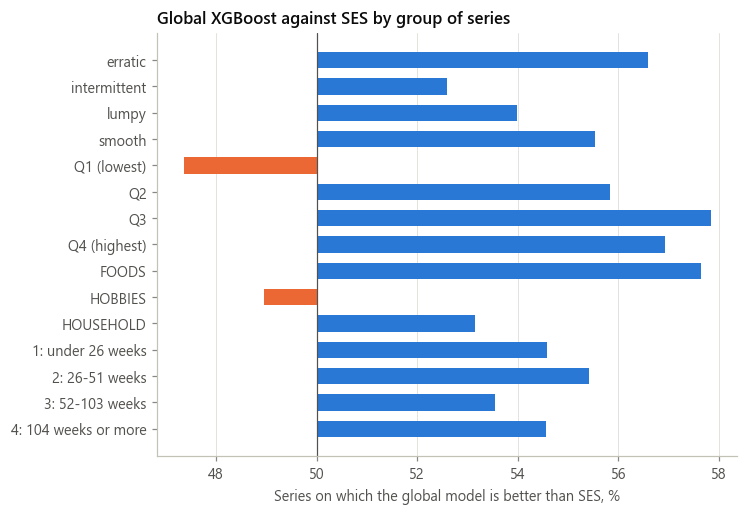

In [9]:
sel = groups[groups["grouping"].isin(["demand class", "sales volume", "category", "history"])].iloc[::-1]
fig, ax = plt.subplots(figsize=(6.8, 5.0))
yy = np.arange(len(sel))
ax.barh(yy, sel["main better than SES, %"] - 50, left=50, height=0.62,
        color=[SERIES[0] if v >= 50 else SERIES[1] for v in sel["main better than SES, %"]])
ax.axvline(50, color=INK_SECONDARY, lw=0.8)
ax.set_yticks(yy, [f"{g}" for g in sel["group"]])
ax.set_xlabel("Series on which the global model is better than SES, %")
ax.set_title("Global XGBoost against SES by group of series")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
savefig(fig, "groups_vs_ses", subdir="weekly")
plt.show()

- The global model wins in all four demand classes, most clearly for smooth and erratic demand.
- It does **not** win for the items with the lowest sales and in HOBBIES, where it is level with SES.
- Its advantage is largest for series with a short history (under a year), where a model of one series has
  little to learn from; these are few, so this is an indication rather than firm evidence.

## 5. Bias

In [10]:
bias = pd.read_csv(RESULTS / "bias.csv")
display(bias.pivot(index="model", columns="window", values="total forecast vs actual, %").loc[MODELS, ORDER].round(1))
b = bias.groupby("model").agg(**{"mean |total bias|, %": ("total forecast vs actual, %", lambda s: s.abs().mean()),
                                 "mean scaled error per series": ("mean scaled error per series", "mean"),
                                 "series over-forecast, %": ("series over-forecast, %", "mean")}).loc[MODELS]
b

window,01.02.-28.02.2016,29.02.-27.03.2016,28.03.-24.04.2016,25.04.-22.05.2016,23.05.-19.06.2016
model,,,,,
XGBoost L+E+S+ID,-2.400,-1.400,-1.000,-3.700,-0.100
"XGBoost L+E+S+ID, default hyperparameters",1.000,-1.000,-0.300,-3.800,1.400
XGBoost L,-4.100,-1.800,-1.100,-2.900,-1.200
ARIMA,-3.800,-1.600,-1.000,-3.600,-1.300
ETS,-3.800,-1.200,-0.700,-3.400,-0.200
SES,-3.800,-1.300,-0.800,-3.400,-0.300
Moving average (4 weeks),-4.300,-0.000,-0.600,-3.400,0.000
Naive,-0.900,-0.900,0.200,-1.500,-0.300
Historical mean,-2.500,-2.400,-3.000,-6.700,-6.300


,"mean |total bias|, %",mean scaled error per series,"series over-forecast, %"
model,,,
XGBoost L+E+S+ID,1.731,-0.037,51.896
"XGBoost L+E+S+ID, default hyperparameters",1.495,-0.021,52.534
XGBoost L,2.232,0.019,54.663
ARIMA,2.252,-0.100,47.821
ETS,1.868,-0.081,48.676
SES,1.919,-0.083,48.753
Moving average (4 weeks),1.675,-0.065,45.862
Naive,0.752,-0.025,39.975
Historical mean,4.169,-0.285,47.505


All methods under-forecast total sales slightly; the differences in bias are small and do not favour either side.

## 6. Few series

How many series does the global model need? XGBoost is tuned and trained on random samples of 100 to 3,000
series only (5 samples per size, `weekly_checks.py subsets`) and scored on these series, test window. The
classical forecasts of the same series do not depend on the sample.

In [11]:
sub = pd.read_csv(RESULTS / "subsets.csv")
test = sub[sub["window"] == ORDER[-1]]
show = ["XGBoost trained on the sample", "XGBoost trained on all series", "SES", "ETS", "ARIMA", "Moving average (4 weeks)", "Naive"]
per_series = test.pivot_table(index="model", columns="series", values="mean RMSSE per series").loc[show]
wrmsse = test.pivot_table(index="model", columns="series", values="WRMSSE").loc[show]
s = test[test["model"] == "XGBoost trained on the sample"].set_index(["series", "sample"])["WRMSSE"]
wins = pd.DataFrame({m: (s < test[test["model"] == m].set_index(["series", "sample"])["WRMSSE"]).groupby("series").sum() for m in ["SES", "ARIMA"]}).T
display(per_series.rename_axis("mean RMSSE per series"), wrmsse.rename_axis("WRMSSE of the sample"),
        wins.rename_axis("samples (of 5) in which the sample model has the lower WRMSSE"))

series,100,300,1000,3000
mean RMSSE per series,,,,
XGBoost trained on the sample,0.818,0.781,0.772,0.769
XGBoost trained on all series,0.768,0.764,0.764,0.763
SES,0.788,0.779,0.782,0.784
ETS,0.794,0.780,0.784,0.786
ARIMA,0.798,0.782,0.784,0.783
Moving average (4 weeks),0.817,0.811,0.813,0.814
Naive,0.959,0.951,0.949,0.950


series,100,300,1000,3000
WRMSSE of the sample,,,,
XGBoost trained on the sample,0.899,0.907,0.667,0.613
XGBoost trained on all series,0.880,0.850,0.668,0.600
SES,0.926,0.788,0.848,0.825
ETS,0.947,0.800,0.847,0.828
ARIMA,0.919,0.805,0.807,0.765
Moving average (4 weeks),0.969,0.880,0.819,0.823
Naive,1.043,0.886,0.991,0.987


series,100,300,1000,3000
samples (of 5) in which the sample model has the lower WRMSSE,,,,
SES,3,3,5,5
ARIMA,3,3,5,5


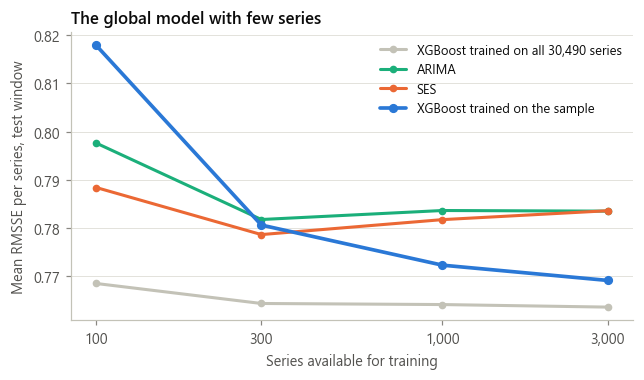

In [12]:
fig, ax = plt.subplots(figsize=(6.6, 3.4))
sizes = list(per_series.columns)
ax.plot(sizes, per_series.loc["XGBoost trained on all series"], color=CONTEXT, lw=2, marker="o", ms=4, label="XGBoost trained on all 30,490 series")
ax.plot(sizes, per_series.loc["ARIMA"], color=SERIES[2], lw=2, marker="o", ms=4, label="ARIMA")
ax.plot(sizes, per_series.loc["SES"], color=SERIES[1], lw=2, marker="o", ms=4, label="SES")
ax.plot(sizes, per_series.loc["XGBoost trained on the sample"], color=SERIES[0], lw=2.4, marker="o", ms=5, label="XGBoost trained on the sample")
ax.set_xscale("log")
ax.set_xticks(sizes, [f"{s:,}" for s in sizes])
ax.minorticks_off()
ax.set_xlabel("Series available for training")
ax.set_ylabel("Mean RMSSE per series, test window")
ax.set_title("The global model with few series")
ax.legend(fontsize=8.5)
savefig(fig, "few_series", subdir="weekly")
plt.show()

With 100 series the global model is worse per series than SES, ETS and ARIMA, with 300 it is level with
them, and from about 1,000 series on it is better in every sample. More series keep helping: the model
trained on all series is better on the same series at every size. WRMSSE of a sample of 100-300 series
varies a lot between samples, so the per-series error is the more reliable measure there.

## Summary

| Question | Answer |
|---|---|
| Accuracy | Global XGBoost is best in all five windows; mean WRMSSE 0.62 against 0.78 for ARIMA |
| Cost | Cheaper per window than ARIMA; tuning is a one-off cost of about one ARIMA run and is not needed to beat the classical methods |
| Where the gain is | Mostly at the aggregate levels; per series small but consistent (52-56% of series) |
| Source of the gain | Mostly the additional inputs; cross-learning from sales alone improves the sums only |
| Limits | No gain for the slowest-selling items and HOBBIES; needs about 1,000 series or more |